In [1]:
#Fichiers Export GeodAir : FOND et 2021-2025 (1er janvier) uniquement -
#! pip install glob
import glob
import pandas as pd

list_fich = sorted(glob.glob("../data/raw/Export_*.csv"))  
print(len(list_fich), "fichiers trouvés")

pollut = []
for f in list_fich:
    temp = pd.read_csv(f, sep=";")                   
    pollut.append(temp)

# empilement vertical des tables issues des exports réalisés à l'identique
ref = pollut[0].columns
problemes = [f for f, t in zip(list_fich, pollut) if not t.columns.equals(ref)]
if problemes:
    raise ValueError(f"PROBLEME de colonnes différentes, fichiers: {problemes}")
df_pollut = pd.concat(pollut, ignore_index=True)

n_init = len(df_pollut)
df_pollut = df_pollut[df_pollut["type d'influence"]=="Fond"]
n_fond = len(df_pollut) 
df_pollut = df_pollut[df_pollut["valeur"] >= 0]
df_pollut=df_pollut.drop_duplicates()
n_sans_dup= len(df_pollut) 
print(n_init, "mesures initiales")
print(n_fond, "mesures 'Fond' seulement")
print(n_sans_dup, "mesures >=0 et sans doublons")

27 fichiers trouvés
1875851 mesures initiales
1821919 mesures 'Fond' seulement
1745462 mesures >=0 et sans doublons


In [2]:
 #RATTACHEMENT GÉOGRAPHIQUE
 #station ──(lat, lon)──► code_dept

import requests
import json
import os

METRO_DEPTS = (
    {f"{i:02d}" for i in range(1, 20)}
    | {'2A', '2B'}
    | {f"{i:02d}" for i in range(21, 96)}
)

def get_departement(lat, lon):
    url = f"https://geo.api.gouv.fr/communes?lat={lat}&lon={lon}&fields=departement"
    r = requests.get(url)
    if r.ok and r.json():
        code = r.json()[0]['departement']['code']
        return code if code in METRO_DEPTS else None
    return None

# Chargement du cache existant
if os.path.exists('sites_dept.json'):
    with open('sites_dept.json') as f:
        resultats = json.load(f)
else:
    resultats = {}

sites = df_pollut[['code site', 'Latitude', 'Longitude']].drop_duplicates('code site').reset_index(drop=True)
nouveaux = sites[~sites['code site'].isin(resultats)]

for k, (_, row) in enumerate(nouveaux.iterrows()):
    if k % 10 == 0:
        print(f"{k}/{len(nouveaux)}")
    resultats[row['code site']] = get_departement(row['Latitude'], row['Longitude'])

# Sauvegarde du cache
with open('sites_dept.json', 'w') as f:
    json.dump(resultats, f)

sites['code_dept'] = sites['code site'].map(resultats)
df_pollut = df_pollut.merge(sites[['code site', 'code_dept']], on='code site', how='left')

In [3]:
print(sites["code_dept"].isna().sum(), "stations sans département")
print(sites[sites["code_dept"].isna()])            # lesquelles ?
print(sites["code_dept"].nunique(), "départements couverts")

#Correction manuelle d'un raté dans l'attribution d'une station...
df_pollut.loc[df_pollut["code site"] == "FR06001", "code_dept"] = "59"
print(df_pollut["code_dept"].isna().sum())

df_pollut.to_csv("../data/processed/Pollution_moy_journaliere_FOND.csv", index=False)

1 stations sans département
    code site  Latitude  Longitude code_dept
188   FR06001  50.35853    3.50804       NaN
90 départements couverts
0


In [4]:
#On repart d'une lecture fraiche, avec un format str imposé pour code_dept
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_pollut =[]
df=pd.read_csv("../data/processed/Pollution_moy_journaliere_FOND.csv",dtype={"code_dept": str})
display(df.head())

,Date de début,Date de fin,Organisme,code zas,Zas,code site,nom site,type d'implantation,Polluant,type d'influence,...,valeur brute,unité de mesure,taux de saisie,couverture temporelle,couverture de données,code qualité,validité,Latitude,Longitude,code_dept
0,2021/01/01 00:00:00,2021/01/01 23:59:59,ATMO AUVERGNE-RHÔNE-ALPES,FR84ZRE01,ZR AUVERGNE-RHONE-ALPES,FR07022,Paray le Fresil,Rurale régionale,NOX as NO2,Fond,...,1.758333,µg-m3,100.0,100,100.0,R,1,46.652668,3.600667,03
1,2021/01/02 00:00:00,2021/01/02 23:59:59,ATMO AUVERGNE-RHÔNE-ALPES,FR84ZRE01,ZR AUVERGNE-RHONE-ALPES,FR07022,Paray le Fresil,Rurale régionale,NOX as NO2,Fond,...,1.979167,µg-m3,100.0,100,100.0,A,1,46.652668,3.600667,03
2,2021/01/03 00:00:00,2021/01/03 23:59:59,ATMO AUVERGNE-RHÔNE-ALPES,FR84ZRE01,ZR AUVERGNE-RHONE-ALPES,FR07022,Paray le Fresil,Rurale régionale,NOX as NO2,Fond,...,3.650000,µg-m3,100.0,100,100.0,A,1,46.652668,3.600667,03
3,2021/01/04 00:00:00,2021/01/04 23:59:59,ATMO AUVERGNE-RHÔNE-ALPES,FR84ZRE01,ZR AUVERGNE-RHONE-ALPES,FR07022,Paray le Fresil,Rurale régionale,NOX as NO2,Fond,...,3.675000,µg-m3,100.0,100,100.0,R,1,46.652668,3.600667,03
4,2021/01/05 00:00:00,2021/01/05 23:59:59,ATMO AUVERGNE-RHÔNE-ALPES,FR84ZRE01,ZR AUVERGNE-RHONE-ALPES,FR07022,Paray le Fresil,Rurale régionale,NOX as NO2,Fond,...,4.229167,µg-m3,100.0,100,100.0,A,1,46.652668,3.600667,03


In [5]:
#AGRÉGATION SPATIALE - PAR DEPARTEMENT
##Contrôles initiaux : id_jour unique, vérification des unités de mesure des polluants
df["jour"] = pd.to_datetime(df["Date de fin"]).dt.normalize()
print(pd.crosstab(df["Polluant"], df["unité de mesure"]))
#Recherche de doublons avec unités de mesure différentes
cles = ["code site", "Date de début", "Polluant"]
print(df.duplicated(subset=cles).sum(), "mesures en double station × jour × polluant")

unité de mesure  P.cm3  mg-m3   µg-m3  µg/m3
Polluant                                    
C6H6                 0      0     365    365
CO                   0   5173       0      0
Chl in PM1           0      0   10658    908
NH4 in PM1           0      0   10798    905
NO2                  0      0  351449   2647
NO3 in PM1           0      0   11060    907
NOX as NO2           0      0  321866    457
Nb PM 10nm        7393      0       0      0
O3                   0      0  420002      0
Org in PM1           0      0   11060    906
PM10                 0      0  309922   9135
PM2.5                0      0  217074   6787
SO2                  0      0   33658      0
SO4 in PM1           0      0   11060    907
0 mesures en double station × jour × polluant


In [6]:
#AGRÉGATION SPATIALE - PAR DEPARTEMENT
##Agrégation par moyenne départementale (journalière)
moy_jour = df.groupby(["code_dept", "jour", "Polluant"])["valeur"].mean()
moy_jour = moy_jour.reset_index()                     
print(moy_jour.head())

  code_dept       jour Polluant  valeur
0        01 2021-01-01      NO2    4.55
1        01 2021-01-01       O3   43.00
2        01 2021-01-01     PM10    7.50
3        01 2021-01-01    PM2.5    9.90
4        01 2021-01-02      NO2    6.05


In [7]:
# AGRÉGATION HEBDOMADAIRE - PAR DÉPARTEMENT
##Agrégation par moyenne départementale hebdomadaire

## 1. Semaine ISO de chaque mesure, au format du Master Dataset (ex. 2021-S01)
iso = df["jour"].dt.isocalendar()
df["date_semaine"] = iso["year"].astype(str) + "-S" + iso["week"].astype(str).str.zfill(2)
print(df[["jour", "date_semaine"]].head())

## 2. Moyenne hebdomadaire par département et polluant
moy_sem = df.groupby(["code_dept", "date_semaine", "Polluant"])["valeur"].mean()
moy_sem = moy_sem.reset_index().rename(columns={"valeur": "moyenne"})
print(moy_sem.head())

## 3. Maximum hebdomadaire par département et polluant
max_sem = df.groupby(["code_dept", "date_semaine", "Polluant"])["valeur"].max()
max_sem = max_sem.reset_index().rename(columns={"valeur": "maximum"})
print(max_sem.head())

## 4. Nombre de mesures par semaine, département et polluant
n_sem = df.groupby(["code_dept", "date_semaine", "Polluant"])["valeur"].count()
n_sem = n_sem.reset_index().rename(columns={"valeur": "n_mesures"})
print(n_sem.head())

## 5. Réunion des trois tables
hebdo = moy_sem.merge(max_sem, on=["code_dept", "date_semaine", "Polluant"])
hebdo = hebdo.merge(n_sem,     on=["code_dept", "date_semaine", "Polluant"])
print(hebdo.head())
print(hebdo.shape)

        jour date_semaine
0 2021-01-01     2020-S53
1 2021-01-02     2020-S53
2 2021-01-03     2020-S53
3 2021-01-04     2021-S01
4 2021-01-05     2021-S01
  code_dept date_semaine Polluant    moyenne
0        01     2020-S53      NO2   6.350000
1        01     2020-S53       O3  36.000000
2        01     2020-S53     PM10  11.166667
3        01     2020-S53    PM2.5  13.966667
4        01     2021-S01      NO2  17.076923
  code_dept date_semaine Polluant  maximum
0        01     2020-S53      NO2      8.7
1        01     2020-S53       O3     44.0
2        01     2020-S53     PM10     18.0
3        01     2020-S53    PM2.5     17.0
4        01     2021-S01      NO2     25.0
  code_dept date_semaine Polluant  n_mesures
0        01     2020-S53      NO2          6
1        01     2020-S53       O3          6
2        01     2020-S53     PM10          6
3        01     2020-S53    PM2.5          3
4        01     2021-S01      NO2         13
  code_dept date_semaine Polluant    moyenne  

208 semaines


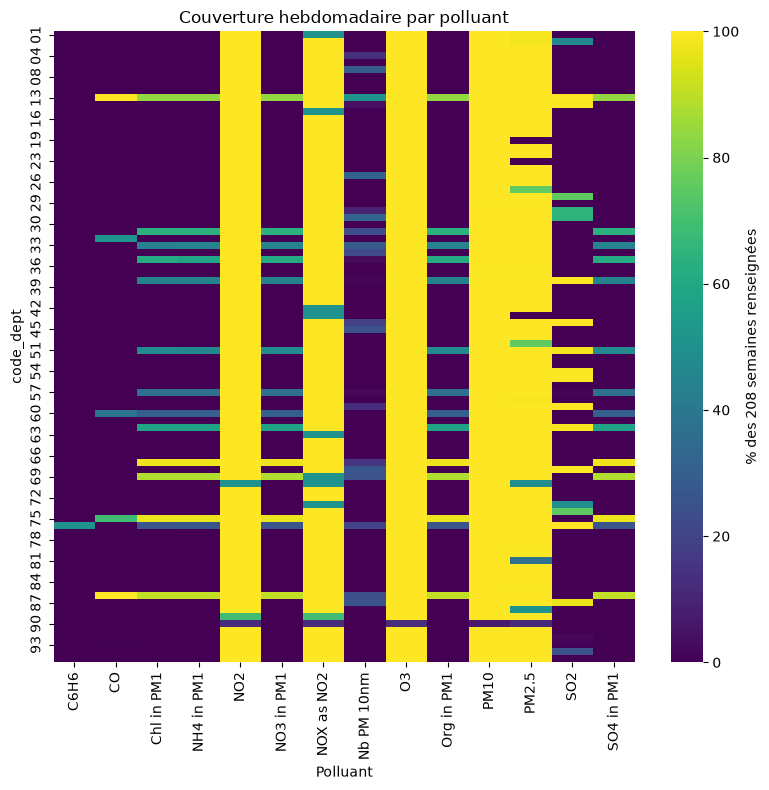

In [9]:
import seaborn as sns

hebdo = hebdo[(hebdo["date_semaine"] >= "2021-S01") & (hebdo["date_semaine"] <= "2024-S52")]
#polluants = df['Polluant'].unique()
#hebdo = hebdo[hebdo["Polluant"].isin(polluants)]
print(hebdo["date_semaine"].nunique(), "semaines")        # attendu : 208

## 7. Couverture : nombre de semaines renseignées par département et polluant
couv = hebdo.groupby(["code_dept", "Polluant"])["date_semaine"].nunique()
couv = couv.unstack(fill_value=0)                          # départements en lignes, polluants en colonnes
couv_pct = 100 * couv / 208                                # en % des 208 semaines
#print(couv_pct.round(0))

plt.figure(figsize=(8, 8))
sns.heatmap(couv_pct, cmap="viridis", vmin=0, vmax=100,
            cbar_kws={"label": "% des 208 semaines renseignées"})
plt.title("Couverture hebdomadaire par polluant")
plt.tight_layout()
plt.show()

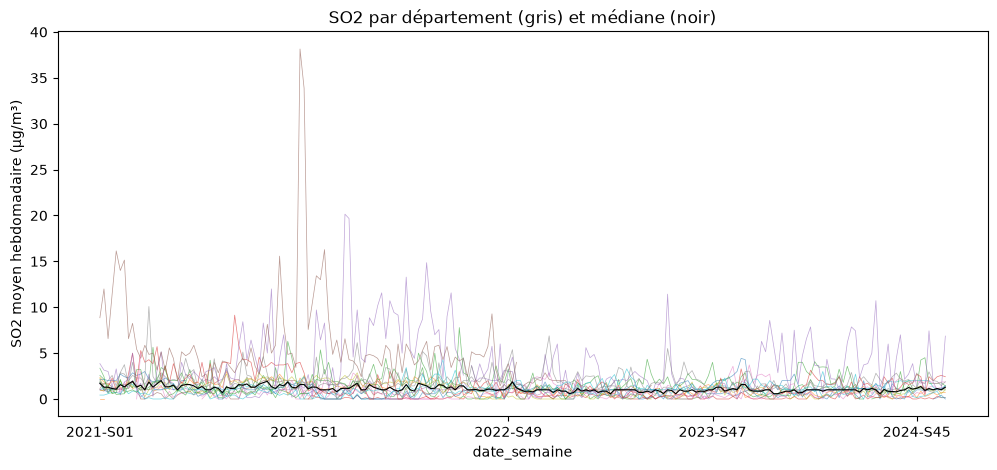

In [10]:
so2 = hebdo[hebdo["Polluant"] == "SO2"]
piv_so2 = so2.pivot(index="date_semaine", columns="code_dept", values="moyenne")

ax = piv_so2.plot(figsize=(12, 5), legend=False, linewidth=0.5, alpha=0.6)
piv_so2.median(axis=1).plot(ax=ax, color="black", linewidth=0.8)
plt.ylabel("SO2 moyen hebdomadaire (µg/m³)")
plt.title("SO2 par département (gris) et médiane (noir)")
plt.show()

In [11]:
n = df.groupby(["Polluant", "code_dept"])["valeur"].count()

# 2. Département "de mesure" si plus de 20 mesures par an en moyenne (4 ans)
est_mesure = (n / 4) > 20

# 3. Nombre de départements de mesure par polluant
print(est_mesure.groupby("Polluant").sum().sort_values(ascending=False))

Polluant
NO2           90
NOX as NO2    90
O3            90
PM10          90
PM2.5         87
SO2           19
Nb PM 10nm    18
Chl in PM1    14
NO3 in PM1    14
NH4 in PM1    14
Org in PM1    14
SO4 in PM1    14
CO             5
C6H6           1
Name: valeur, dtype: int64


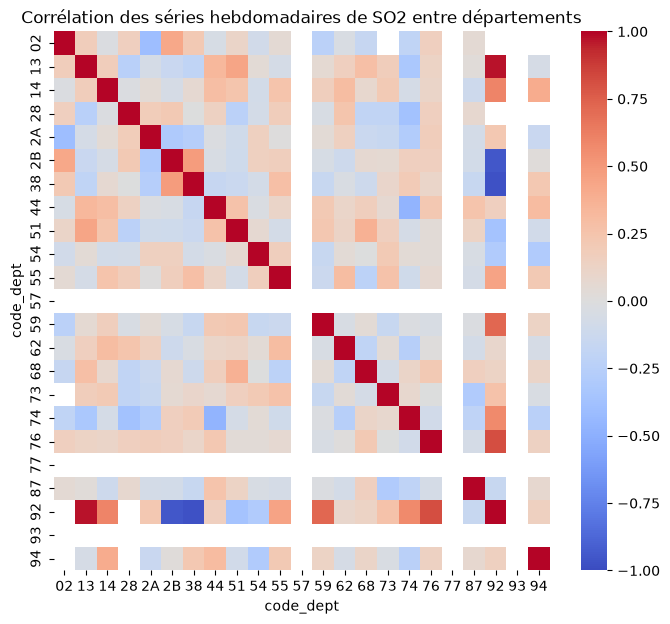

Corrélation médiane entre départements : 0.04


In [49]:
corr = piv_so2.corr()

plt.figure(figsize=(8, 7))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Corrélation des séries hebdomadaires de SO2 entre départements")
plt.show()
print("Corrélation médiane entre départements :", round(corr.where(~np.eye(len(corr), dtype=bool)).stack().median(), 2))